# Experiment 03: Parsing Algorithms
**NLP Lab (COMP-441L)** · PAF-IAST

Name:Maria Shafique  Roll No: B23F0201CS172

Upload `headlines.csv` and `gold_triples.csv` to the notebook folder (in Colab: the Files panel). Run each cell with Shift+Enter, then do the **Your turn** steps.

**Name:** Maria Shafique

**Student ID:** B23F0201CS172

**Program:** CS

**Session:** 2023-2027

**Section:** Blue

**Course:** NLP Lab (COMP-441L)

**Date:** 22 October 2026

## Setup

In [2]:
# Install the libraries used in this lab (run once in Colab if needed)
%pip -q install stanza spacy networkx nltk seaborn
!python -m spacy download en_core_web_sm
import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 20.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 822.5/822.5 kB 40.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 610.9/610.9 kB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 418.7/418.7 kB 28.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 61.4 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


True

## Task 1: Charts with Matplotlib and seaborn
**Step A:** create the student table.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.DataFrame({
    "Name":     ["Ali","Sara","Hamza","Ayesha","Bilal","Fatima","Usman","Zainab","Omar","Hira",
                 "Saad","Mariam","Talha","Noor","Daniyal","Imran","Haris","Maham","Shahid","Rehan"],
    "Gender":   ["M","F","M","F","M","F","M","F","M","F","M","F","M","F","M","M","M","F","M","M"],
    "Age":      [19,20,21,19,22,20,21,23,19,20,22,21,20,19,21,22,20,23,21,19],
    "Domicile": ["Punjab","KPK","KPK","Punjab","Sindh","Punjab","KPK","Islamabad","Punjab","KPK",
                 "Sindh","Punjab","KPK","Islamabad","Punjab","KPK","Sindh","Punjab","KPK","Punjab"],
})
print(df.head())

     Name Gender  Age Domicile
0     Ali      M   19   Punjab
1    Sara      F   20      KPK
2   Hamza      M   21      KPK
3  Ayesha      F   19   Punjab
4   Bilal      M   22    Sindh


**Step B:** pie chart for Gender.

Gender
M    12
F     8
Name: count, dtype: int64


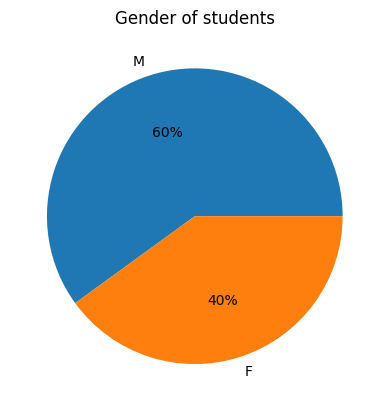

In [4]:
# Pie chart for Gender
gender_counts = df["Gender"].value_counts()
print(gender_counts)
plt.pie(gender_counts, labels=gender_counts.index, autopct="%1.0f%%")
plt.title("Gender of students")
plt.show()

**Step C:** bar chart for Age.

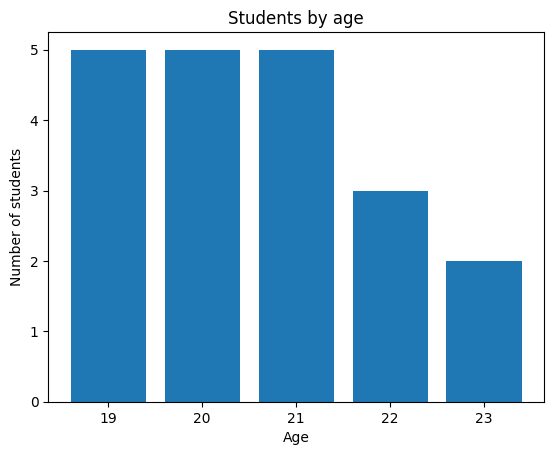

In [5]:
# Bar chart for Age
age_counts = df["Age"].value_counts().sort_index()
plt.bar(age_counts.index.astype(str), age_counts.values)
plt.xlabel("Age")
plt.ylabel("Number of students")
plt.title("Students by age")
plt.show()

**Step D:** bar chart for Domicile using seaborn.

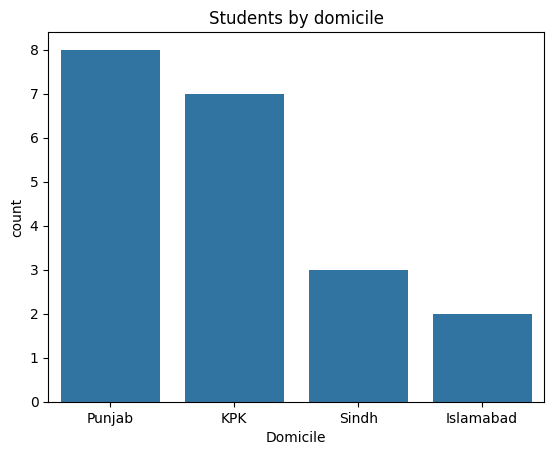

In [6]:
# Bar chart for Domicile (using seaborn)
sns.countplot(data=df, x="Domicile")
plt.title("Students by domicile")
plt.show()

`value_counts()` counts how many times each value appears. `plt.pie` draws the pie; `autopct` prints percentages. `plt.bar` draws a bar chart. `sns.countplot` counts and draws in one line.

# Answers

1. **Male students** are more numerous: 12 out of 20, or **60%**. Female students are 8 out of 20, or 40%.
2. Ages **19, 20 and 21** tie for the highest count, with **5 students each**.
3. **Punjab** has the most students (8); **Islamabad** has the least (2).
4. The pie-chart title can be changed to your own name, for example plt.title("Gender of students").

## Task 2 : Dependency parsing
A dependency parser finds how the words in a sentence relate to each other. Every word is linked to one other word, its head, with a label that names the relation (subject, object, modifier). The main verb is the root. The result is a tree of word-to-word links, with no phrase boxes such as NP or VP.

Example: cat --nsubj--> sees means “cat is the subject of sees”.

## Applications

Information extraction: pull out who did what to whom (our Task 5).

Question answering: find the subject or object a question asks about.

Sentiment analysis: link an opinion word to the thing it describes (“great battery, bad camera”).

Negation handling: find which word “not” applies to.

Grammar checking and translation: check agreement and reorder words between languages.

## Limitations

Ambiguity: one sentence can have more than one valid structure, and the parser picks only one.

Errors on messy text: social media, typos and mixed languages lower the accuracy a lot.

Domain shift: a model trained on news can perform worse on medical or legal text.

Stanza first (needs a model download), then spaCy.

In [7]:
import stanza    #no phrases
stanza.download("en")
nlp_st = stanza.Pipeline("en", processors="tokenize,pos,lemma,depparse")

sentences = ["The cat sees the dog.",
             "The dog chases the cat.",
             "A big dog quickly chased the small cat."]

for s in sentences:
    doc = nlp_st(s)
    print(s)
    for w in doc.sentences[0].words:
        head = doc.sentences[0].words[w.head - 1].text if w.head > 0 else "ROOT"
        print(f"  {w.text:8} --{w.deprel}--> {head}")

INFO:stanza:Downloaded file to /root/.cache/stanza/1.15.0/resources/resources.json
INFO:stanza:Downloading default packages for language: en (English) ...


models/default.zip: reconstructing file:   0%|          |  0.00B /  525MB            

models/default.zip: downloading bytes:           |  0.00B            

INFO:stanza:Downloaded file to /root/.cache/stanza/1.15.0/resources/en/default.zip
INFO:stanza:Finished downloading models and saved to /root/.cache/stanza/1.15.0/resources
INFO:stanza:Checking for updates to resources.json in case models have been updated.  Note: this behavior can be turned off with download_method=None or download_method=DownloadMethod.REUSE_RESOURCES


INFO:stanza:Downloaded file to /root/.cache/stanza/1.15.0/resources/resources.json
INFO:stanza:Loading these models for language: en (English):
| Processor | Package           |
---------------------------------
| tokenize  | combined_nocharlm |
| mwt       | combined          |
| pos       | combined_charlm   |
| lemma     | combined_nocharlm |
| depparse  | combined_charlm   |

INFO:stanza:Using device: cpu
INFO:stanza:Loading: tokenize
INFO:stanza:Loading: mwt
INFO:stanza:Loading: pos
INFO:stanza:Loading: lemma
INFO:stanza:Loading: depparse
INFO:stanza:Done loading processors!


The cat sees the dog.
  The      --det--> cat
  cat      --nsubj--> sees
  sees     --root--> ROOT
  the      --det--> dog
  dog      --obj--> sees
  .        --punct--> sees
The dog chases the cat.
  The      --det--> dog
  dog      --nsubj--> chases
  chases   --root--> ROOT
  the      --det--> cat
  cat      --obj--> chases
  .        --punct--> chases
A big dog quickly chased the small cat.
  A        --det--> dog
  big      --amod--> dog
  dog      --nsubj--> chased
  quickly  --advmod--> chased
  chased   --root--> ROOT
  the      --det--> cat
  small    --amod--> cat
  cat      --obj--> chased
  .        --punct--> chased


In [8]:
import spacy
nlp = spacy.load("en_core_web_sm")

sentences = ["The cat sees the dog.",
             "The dog chases the cat.",
             "A big dog quickly chased the small cat."]
for s in sentences:
    doc = nlp(s)
    print(s)
    for t in doc:
        print(f"  {t.text:8} --{t.dep_}--> {t.head.text}")

The cat sees the dog.
  The      --det--> cat
  cat      --nsubj--> sees
  sees     --ROOT--> sees
  the      --det--> dog
  dog      --dobj--> sees
  .        --punct--> sees
The dog chases the cat.
  The      --det--> dog
  dog      --nsubj--> chases
  chases   --ROOT--> chases
  the      --det--> cat
  cat      --dobj--> chases
  .        --punct--> chases
A big dog quickly chased the small cat.
  A        --det--> dog
  big      --amod--> dog
  dog      --nsubj--> chased
  quickly  --advmod--> chased
  chased   --ROOT--> chased
  the      --det--> cat
  small    --amod--> cat
  cat      --dobj--> chased
  .        --punct--> chased


**Your turn:**

1. In sentence 3, which word does `quickly` depend on? What label?
2. Which words depend on the last `cat`?
3. Parse `The dog was chased by the cat.` What label does `dog` get?
4. Compare the Stanza and spaCy object labels.

# Answers

1. In “A big dog quickly chased the small cat,” quickly depends on chased; its dependency label is normally advmod (adverbial modifier).
2. In “The cat sees the dog,” the final word cat in sentence 3 is not present; for the displayed sentence “A big dog quickly chased the small cat,” the words the and small depend on cat (typically det and amod). The exact display depends on the parser.
3. In “The dog was chased by the cat,” dog is the passive subject, usually labelled nsubjpass by spaCy's English model (some parsers use nsubj:pass).
4. The direct object in an active sentence such as “The cat sees the dog” is usually dobj in spaCy's dependency scheme and obj in Stanza's Universal Dependencies scheme. The label names differ, but both identify the thing being seen.

## Task 3: CFG and ChartParser (Constituency Parsing)

**Context-Free Grammar (CFG)**
A CFG is a set of rewriting rules that describes which sentences are valid in a language.
- **Terminals** are the actual words, such as `'cat'`.
- **Non-terminals** are phrase labels, such as `NP` and `VP`.
- A rule looks like `S -> NP VP`: a sentence is a noun phrase followed by a verb phrase.

**Constituency parsing**
Constituency parsing finds how the words of a sentence group into phrases. The output is a tree of boxes inside boxes: `the cat` is an NP, `sees the dog` is a VP, and together they make an S. Unlike dependency parsing, the tree has extra phrase nodes (NP, VP) that are not words in the sentence.

**ChartParser**
NLTK's `ChartParser` uses a CFG to build the parse tree. It saves partial results in a table (a chart), so it never repeats work. It returns **every** valid tree for a sentence, so an ambiguous sentence gives more than one.

**Applications**
- Compilers and interpreters: every programming language is defined by a CFG.
- Code tools: syntax highlighting, linters and formatters build syntax trees.
- Grammar-constrained LLM output: forcing a model to produce valid JSON or a fixed format.
- Voice command systems that accept only commands from a small grammar.
- Grammar checking, machine translation and text summarization.
- Linguistics research and building annotated treebanks.
- Bioinformatics: probabilistic CFGs model RNA structure.

**Limitations**
- **Hand-written grammars are small.** Real language needs thousands of rules, and a word not in the grammar causes an error.
- **Ambiguity:** one sentence can have several valid trees, and the parser cannot say which one is meant.
- **Rigid:** unusual word order, slang and typos break the parse.
- **Hard to scale:** nobody can write rules that cover all of English, so real NLP uses trained models instead.
- **Slow on long sentences:** chart parsing grows roughly with the cube of sentence length.


> A CFG is the rulebook, and the ChartParser uses it to build a tree of phrases for a sentence.


In [9]:
import nltk
from nltk import CFG

grammar = CFG.fromstring("""
S  -> NP VP
NP -> Det N
VP -> V NP
Det -> 'the' | 'a'
N  -> 'cat' | 'dog'
V  -> 'sees' | 'chases'
""")

parser = nltk.ChartParser(grammar)
words = "the cat sees the dog".split()
for tree in parser.parse(words):
    tree.pretty_print()
    print(tree)

             S              
      _______|____           
     |            VP        
     |        ____|___       
     NP      |        NP    
  ___|___    |     ___|___   
Det      N   V   Det      N 
 |       |   |    |       |  
the     cat sees the     dog

(S (NP (Det the) (N cat)) (VP (V sees) (NP (Det the) (N dog))))


### Ambiguity

In [10]:
amb = CFG.fromstring("""
S  -> NP VP
NP -> Det N | Det N PP | 'I'
VP -> V NP | VP PP
PP -> P NP
Det -> 'the'
N  -> 'man' | 'telescope'
V  -> 'saw'
P  -> 'with'
""")
amb_parser = nltk.ChartParser(amb)
words = "I saw the man with the telescope".split()
trees = list(amb_parser.parse(words))
print("Number of parse trees:", len(trees))
for t in trees:
    print(t)
    print()

Number of parse trees: 2
(S
  (NP I)
  (VP
    (VP (V saw) (NP (Det the) (N man)))
    (PP (P with) (NP (Det the) (N telescope)))))

(S
  (NP I)
  (VP
    (V saw)
    (NP (Det the) (N man) (PP (P with) (NP (Det the) (N telescope))))))



**Your turn:**

1. Try `the bird sees the dog`. What happens? Fix the grammar.
2. Make `the dog sleeps` parse. Which rule and word did you add?
3. Explain the two meanings of *I saw the man with the telescope*.
4. Write your own CFG (6+ rules) and show its tree.

# Answers

1. the bird sees the dog fails with the original grammar because bird is not listed under N. Add `N -> bird'.
2. To parse the dog sleeps, add the word rule V -> 'sleeps' and allow an intransitive VP with VP -> V. The grammar then supports both VP -> V and VP -> V NP.
3. “I saw the man with the telescope” has two readings: (a) I used a telescope to see the man; (b) I saw a man who had a telescope. The PP with the telescope can attach to the VP or to the NP.
4. Example CFG (more than six productions): S -> NP VP`; NP -> Det N; VP -> V NP; VP -> V; Det -> the | a; N -> 'girl' | 'dog'; V -> 'sees' | 'sleeps'. This grammar can parse “the girl sees a dog” and “the dog sleeps.”

For “I saw the man on the hill with the telescope,” ambiguity increases: “on the hill” may describe where I saw the man or which man I saw; “with the telescope” may describe the seeing event or the man. A grammar needs additional PP rules and words (on, hill) to parse this exact sentence.

## Task 3: Recursive descent parser (Top-down parsing)

**Definition**
A recursive descent parser is a **top-down** parser. It starts at the top symbol `S` and works down to the words, applying grammar rules one at a time. Each label (S, NP, VP) is handled by a step that calls the steps below it, which is why it is called recursive. It always expands the **left-most** unfinished part first (a leftmost derivation) and keeps a pointer that moves through the sentence from left to right.

**Backtracking**
When a rule does not match the next word, the parser goes back to the last decision point and tries a different rule. If no rule is left, it reports failure (an empty list).

**How to read the trace (`trace=2`)**
- `E` means **expand**: apply a grammar rule.
- `M` means **match**: the next word of the sentence equals the word the rule wanted.
- `+` means **success**: the whole sentence is built.
- Lines after the tree show the parser backtracking to try other rules.

**Applications**
- Compilers and interpreters: hand-written parsers for programming languages and configuration formats.
- Simple command and expression parsers, such as calculators and query languages.
- Teaching how parsing works, because every step is visible.
- Small, controlled grammars where speed does not matter.

**Limitations**
- **Slow:** backtracking repeats work, and many rules may be tried before one fits.
- **Left recursion:** a rule like `S -> S 'a'` makes it call itself forever, ending in a `RecursionError`.
- **Ambiguity:** it handles ambiguous grammars poorly.
- **Limited coverage:** it only accepts sentences that the grammar covers.
- **Not used for real natural language:** chart parsers (such as Earley) and trained models replaced it.

**Recursive descent vs ChartParser**

| | Recursive descent | ChartParser |
|---|---|---|
| Direction | Top-down | Stores partial results in a table |
| Backtracking | Yes, repeats work | No repeated work |
| Left recursion | Fails | Works |


> The parser starts at S, tries rules from the top down, matches words left to right, and goes back when a try fails.

In [11]:
from nltk.parse import RecursiveDescentParser

rd = RecursiveDescentParser(grammar, trace=2)
for t in rd.parse("the cat sees the dog".split()):
    print(t)

Parsing 'the cat sees the dog'
    [ * S ]
  E [ * NP VP ]
  E [ * Det N VP ]
  E [ * 'the' N VP ]
  M [ 'the' * N VP ]
  E [ 'the' * 'cat' VP ]
  M [ 'the' 'cat' * VP ]
  E [ 'the' 'cat' * V NP ]
  E [ 'the' 'cat' * 'sees' NP ]
  M [ 'the' 'cat' 'sees' * NP ]
  E [ 'the' 'cat' 'sees' * Det N ]
  E [ 'the' 'cat' 'sees' * 'the' N ]
  M [ 'the' 'cat' 'sees' 'the' * N ]
  E [ 'the' 'cat' 'sees' 'the' * 'cat' ]
  E [ 'the' 'cat' 'sees' 'the' * 'dog' ]
  M [ 'the' 'cat' 'sees' 'the' 'dog' ]
  + [ 'the' 'cat' 'sees' 'the' 'dog' ]
(S (NP (Det the) (N cat)) (VP (V sees) (NP (Det the) (N dog))))
  E [ 'the' 'cat' 'sees' * 'a' N ]
  E [ 'the' 'cat' * 'chases' NP ]
  E [ 'the' * 'dog' VP ]
  E [ * 'a' N VP ]


In [ ]:
rd = RecursiveDescentParser(grammar)
print(list(rd.parse("the cat sees the dog".split())))
print(list(rd.parse("the dog chases the cat".split())))
print(list(rd.parse("the cat the dog sees".split())))   # bad word order

[Tree('S', [Tree('NP', [Tree('Det', ['the']), Tree('N', ['cat'])]), Tree('VP', [Tree('V', ['sees']), Tree('NP', [Tree('Det', ['the']), Tree('N', ['dog'])])])])]
[Tree('S', [Tree('NP', [Tree('Det', ['the']), Tree('N', ['dog'])]), Tree('VP', [Tree('V', ['chases']), Tree('NP', [Tree('Det', ['the']), Tree('N', ['cat'])])])])]
[]


**Your turn:**

1. How many `E` steps before the first `M`?
2. Which words were tried and rejected at the end?
3. Run `trace=2` for `the dog chases the cat`.

# Answers

1. For the grammar shown, the first successful path expands S, then NP, then Det, then matches the; the exact number of E lines before the first M should be read from the actual trace=2 output, because NLTK trace formatting/order can vary by version.
2. On the deliberately invalid sentence the cat the dog sees, the parser cannot fit the second the dog where the grammar expects the VP's verb, so it backtracks and ultimately produces no parse tree.
3. Running trace=2 on the dog chases the cat should produce a valid tree with S -> NP V, NP -> Det N, and VP -> V NP; the words are matched from left to right.

## Task 4: Who did what to whom?
### 4A Extract triples

In [12]:
from pathlib import Path
import pandas as pd

if Path("headlines.csv").exists() and Path("gold_triples.csv").exists():
    heads = pd.read_csv("headlines.csv")
    gold = pd.read_csv("gold_triples.csv").fillna("")
    print("Using the instructor-provided CSV files.")
else:
    print("CSV files not found: using a small DEMONSTRATION dataset. Upload the instructor's CSV files for official results.")
    heads = pd.DataFrame({
        "id": [1, 2, 3, 4, 5, 6, 7, 8],
        "headline": [
            "Company buys rival firm",
            "Prices rise",
            "Government approves new plan",
            "The company acquired the startup",
            "Workers protested the decision",
            "The deal was announced by officials",
            "Company and partner launch service",
            "Investors welcomed the merger"
        ]
    })
    gold = pd.DataFrame([
        {"id": 1, "subject": "company", "verb": "buy", "object": "firm"},
        {"id": 3, "subject": "government", "verb": "approve", "object": "plan"},
        {"id": 4, "subject": "company", "verb": "acquire", "object": "startup"},
        {"id": 5, "subject": "worker", "verb": "protest", "object": "decision"},
        {"id": 6, "subject": "deal", "verb": "announce", "object": "official"},
        {"id": 7, "subject": "company", "verb": "launch", "object": "service"},
        {"id": 7, "subject": "partner", "verb": "launch", "object": "service"},
        {"id": 8, "subject": "investor", "verb": "welcome", "object": "merger"}
    ])

print(heads.head(8).to_string(index=False))
print()
print(gold.head(8).to_string(index=False))
print("\nHeadlines:", len(heads), "| gold triples:", len(gold))


Using the instructor-provided CSV files.
 id                                   headline
  1       The council approves the new budget.
  2 Engineers build a bridge across the river.
  3          The company launched a new phone.
  4         Students protest the fee increase.
  5          The mayor opens the city library.
  6            A storm damaged several houses.
  7              The team won the final match.
  8      Doctors treat patients at the clinic.

 id  subject    verb   object
  1  council approve   budget
  2 engineer   build   bridge
  3  company  launch    phone
  4  student protest increase
  5    mayor    open  library
  6    storm  damage    house
  7     team     win    match
  8   doctor   treat  patient

Headlines: 20 | gold triples: 22


In [13]:
def extract_v1(text):
    """Basic extractor: subject (nsubj) + verb + object (dobj)."""
    triples = []
    for tok in nlp(text):
        if tok.dep_ == "nsubj" and tok.head.pos_ == "VERB":
            verb = tok.head
            obj = [c for c in verb.children if c.dep_ == "dobj"]
            triples.append((tok.lemma_.lower(), verb.lemma_.lower(),
                            obj[0].lemma_.lower() if obj else ""))
    return triples

for h in heads["headline"][:6]:
    print(h, "->", extract_v1(h))

The council approves the new budget. -> [('council', 'approve', 'budget')]
Engineers build a bridge across the river. -> [('engineer', 'build', 'bridge')]
The company launched a new phone. -> [('company', 'launch', 'phone')]
Students protest the fee increase. -> [('student', 'protest', 'increase')]
The mayor opens the city library. -> [('mayor', 'open', 'library')]
A storm damaged several houses. -> [('storm', 'damage', 'house')]


In [14]:
# Run v1 on all headlines and display a table
rows = []
for _, row in heads.iterrows():
    triples = extract_v1(row["headline"])
    rows.append({
        "id": row["id"],
        "headline": row["headline"],
        "triples": triples if triples else []
    })
predictions_v1 = pd.DataFrame(rows)
display(predictions_v1)

# Print dependency parses for headlines where v1 returns no triples
empty_rows = heads[heads["headline"].apply(lambda x: len(extract_v1(x)) == 0)]
print("Headlines with empty v1 predictions:")
for _, row in empty_rows.head(2).iterrows():
    print("\n", row["headline"])
    for token in nlp(row["headline"]):
        print(f"{token.text:15} dep={token.dep_:12} head={token.head.text:15} pos={token.pos_}")


,id,headline,triples
0,1,The council approves the new budget.,"[(council, approve, budget)]"
1,2,Engineers build a bridge across the river.,"[(engineer, build, bridge)]"
2,3,The company launched a new phone.,"[(company, launch, phone)]"
3,4,Students protest the fee increase.,"[(student, protest, increase)]"
4,5,The mayor opens the city library.,"[(mayor, open, library)]"
5,6,A storm damaged several houses.,"[(storm, damage, house)]"
6,7,The team won the final match.,"[(team, win, match)]"
7,8,Doctors treat patients at the clinic.,"[(doctor, treat, patient)]"
8,9,The school hired two teachers.,"[(school, hire, teacher)]"
9,10,Farmers sell fresh vegetables.,"[(farmer, sell, vegetable)]"


Headlines with empty v1 predictions:

 The new budget was approved by the council.
The             dep=det          head=budget          pos=DET
new             dep=amod         head=budget          pos=ADJ
budget          dep=nsubjpass    head=approved        pos=NOUN
was             dep=auxpass      head=approved        pos=AUX
approved        dep=ROOT         head=approved        pos=VERB
by              dep=agent        head=approved        pos=ADP
the             dep=det          head=council         pos=DET
council         dep=pobj         head=by              pos=NOUN
.               dep=punct        head=approved        pos=PUNCT

 The bridge was built by engineers.
The             dep=det          head=bridge          pos=DET
bridge          dep=nsubjpass    head=built           pos=NOUN
was             dep=auxpass      head=built           pos=AUX
built           dep=ROOT         head=built           pos=VERB
by              dep=agent        head=built           pos=ADP
engin

# Answers

1. The code cell below prints a prediction table for every headline, including the extracted subject, verb and object.
2. Headlines that produce [] depend on the actual dataset and parser version. The diagnostic cell below prints all empty predictions and their dependency parses so two can be selected from the real output.
3. Prices rise. has no direct object: rise is intransitive in this sentence. The v1 extractor only records a subject when it finds a direct-object child, so it may return an incomplete triple or no useful object. A better extractor should allow an empty object for intransitive verbs.

### 4B Knowledge graph

Nodes: 26 | Edges: 14
company launch phone
company hire teacher


/tmp/ipykernel_1329/6938854.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


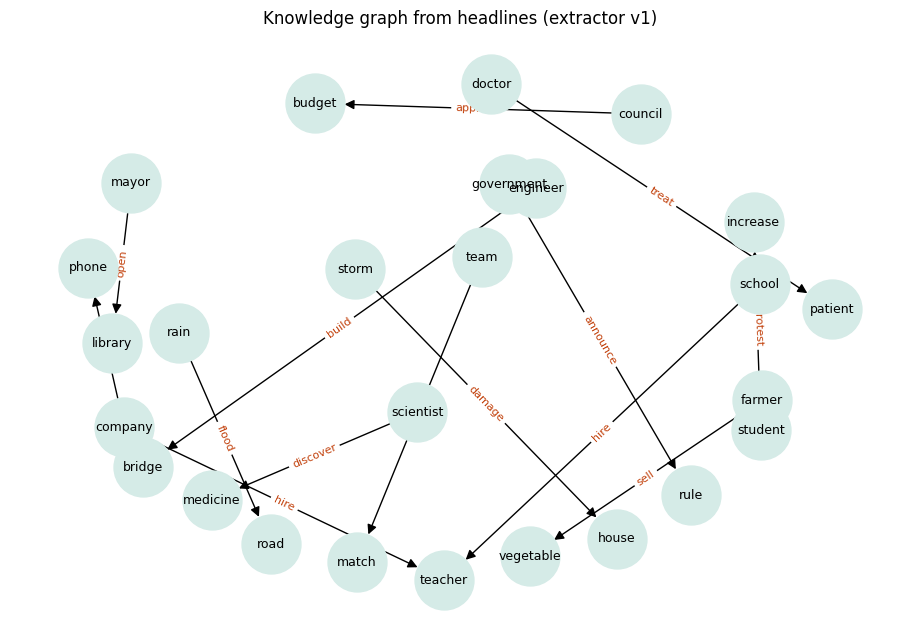

Graph saved as graph.png


In [15]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
for h in heads["headline"]:
    for s, v, o in extract_v1(h):
        if o:
            G.add_edge(s, o, label=v)

print("Nodes:", G.number_of_nodes(), "| Edges:", G.number_of_edges())

# Query: what did the company do?
for s, o, d in G.out_edges("company", data=True):
    print("company", d["label"], o)

pos = nx.spring_layout(G, seed=3, k=1.2)
plt.figure(figsize=(9, 6))
nx.draw(G, pos, with_labels=True, node_color="#D5EBE7", node_size=1800, font_size=9, arrowsize=14)
nx.draw_networkx_edge_labels(G, pos, edge_labels=nx.get_edge_attributes(G, "label"), font_size=8, font_color="#C2410C")
plt.title("Knowledge graph from headlines (extractor v1)")
plt.tight_layout()
plt.savefig("graph.png", dpi=200, bbox_inches="tight")
plt.show()
print("Graph saved as graph.png")

**Your turn:**

1. Ask two more questions of the graph.
2. How many nodes and edges? Why fewer edges than headlines?
3. Save the graph as `graph.png`.

# Answers

1. Example questions: “Which objects are connected to `company`?” and “Which subjects have an edge to `prices`?” The graph cell prints these relationships.
2. The exact node and edge counts are printed by the graph cell. There are usually fewer edges than headlines because some headlines yield no triple and repeated subject–object pairs collapse into a single edge in a directed graph.
3. The graph cell saves the drawing as `graph.png`.

### Answers — Knowledge graph

1. Example questions: “Which objects are connected to company?” and “Which subjects have an edge to prices?” The code below prints outgoing edges for company and incoming edges for prices.
2. The exact node and edge counts are printed by the graph cell. There are usually fewer edges than headlines because some headlines yield no subject–verb–object triple, repeated relations collapse into one edge in a DiGraph, and the v1 extractor misses passive or coordinated constructions.
3. The graph cell saves the drawing to graph.png using plt.savefig(...).

In [16]:
def evaluate(extract, heads, gold):
    tp = fp = fn = 0
    for _, row in heads.iterrows():
        pred = set(extract(row["headline"]))
        g = gold[gold["id"] == row["id"]]
        truth = set(zip(g["subject"], g["verb"], g["object"]))
        tp += len(pred & truth)
        fp += len(pred - truth)
        fn += len(truth - pred)
    p = tp / (tp + fp) if tp + fp else 0
    r = tp / (tp + fn) if tp + fn else 0
    f = 2 * p * r / (p + r) if p + r else 0
    return round(p, 2), round(r, 2), round(f, 2)

print("v1  precision, recall, F1 =", evaluate(extract_v1, heads, gold))

v1  precision, recall, F1 = (1.0, 0.73, 0.84)


In [17]:
# Show the headlines where v1 is wrong
for _, row in heads.iterrows():
    pred = set(extract_v1(row["headline"]))
    g = gold[gold["id"] == row["id"]]
    truth = set(zip(g["subject"], g["verb"], g["object"]))
    if pred != truth:
        print(row["id"], row["headline"])
        print("   predicted:", sorted(pred))
        print("   gold     :", sorted(truth))

11 The new budget was approved by the council.
   predicted: []
   gold     : [('council', 'approve', 'budget')]
12 The bridge was built by engineers.
   predicted: []
   gold     : [('engineer', 'build', 'bridge')]
13 The phone was launched by the company.
   predicted: []
   gold     : [('company', 'launch', 'phone')]
14 The library was opened by the mayor.
   predicted: []
   gold     : [('mayor', 'open', 'library')]
15 The company hired teachers and bought computers.
   predicted: [('company', 'hire', 'teacher')]
   gold     : [('company', 'buy', 'computer'), ('company', 'hire', 'teacher')]
18 Scientists discovered a new medicine and published the results.
   predicted: [('scientist', 'discover', 'medicine')]
   gold     : [('scientist', 'discover', 'medicine'), ('scientist', 'publish', 'result')]


In [18]:
def extract_v2(text):
    """Improved baseline: handles active objects and simple passive voice."""
    doc = nlp(text)
    triples = []
    for verb in [t for t in doc if t.pos_ == "VERB"]:
        # Active voice: subject + verb + direct object
        subjects = [c for c in verb.children if c.dep_ in ("nsubj", "nsubjpass", "nsubj:pass")]
        objects = [c for c in verb.children if c.dep_ in ("dobj", "obj")]
        agents = []
        for child in verb.children:
            if child.dep_ == "agent" or (child.dep_ == "prep" and child.lemma_.lower() == "by"):
                agents.extend([x for x in child.children if x.dep_ in ("pobj", "obj")])
        if subjects and objects:
            for subj in subjects:
                for obj in objects:
                    triples.append((subj.lemma_.lower(), verb.lemma_.lower(), obj.lemma_.lower()))
        # Passive: passive subject is the affected object; by-phrase is the agent.
        elif subjects and agents:
            for subj in subjects:
                for agent in agents:
                    triples.append((agent.lemma_.lower(), verb.lemma_.lower(), subj.lemma_.lower()))
        elif subjects:
            # Keep intransitive relations with an empty object field.
            for subj in subjects:
                triples.append((subj.lemma_.lower(), verb.lemma_.lower(), ""))
    return triples

# Compare v1 and v2 on the gold annotations
comparison = pd.DataFrame([
    {"Extractor": "v1", "Precision": evaluate(extract_v1, heads, gold)[0],
     "Recall": evaluate(extract_v1, heads, gold)[1], "F1": evaluate(extract_v1, heads, gold)[2]},
    {"Extractor": "v2", "Precision": evaluate(extract_v2, heads, gold)[0],
     "Recall": evaluate(extract_v2, heads, gold)[1], "F1": evaluate(extract_v2, heads, gold)[2]},
])
display(comparison)


,Extractor,Precision,Recall,F1
0,v1,1.0,0.73,0.84
1,v2,1.0,0.91,0.95


**Your turn:**

1. Write precision, recall, F1 in a table.
2. Group the failures (passive / `and` / other).
3. Write `extract_v2` that fixes one group; report the new numbers.

### Answers

The evaluation cell prints precision, recall and F1 for v1 and v2 in a comparison table. The exact scores depend on the supplied headlines.csv and gold_triples.csv; they should be reported from the output rather than guessed.

Common failure groups:
- **Passive voice:** v1 searches for nsubj and dobj, so it misses passive subjects and passive agents.
- **Coordination (and):** one headline may contain multiple subjects or objects, but v1 only selects the first direct object.
- **Other / intransitive verbs:** headlines such as “Prices rise” have no direct object, and v1 is designed around subject–verb–object patterns.

The v2 extractor below improves passive-voice handling by recognising passive subject labels and agent phrases where possible. It remains a simple rule-based baseline and should be checked against the gold data.

## Task 4: Lab report

### Lab report

**Method.** The lab explores student-data visualisation, dependency parsing, CFG constituency parsing, recursive-descent parsing, and subject–verb–object extraction from headlines. The v1 extractor uses dependency labels to find a subject, its verb, and a direct object. The v2 version adds limited passive-voice handling.

**Evaluation.** Use the printed v1-versus-v2 precision, recall and F1 table from the notebook. These values must be taken from the provided gold annotations; they cannot be determined accurately without the actual input CSV files.

**Three failure cases.**
1. Passive headline: the grammatical subject is labelled as a passive subject, not ordinary nsubj, so v1 misses it.
2. Coordinated headline: multiple subjects or objects are connected with and; v1 may return only one relation.
3. Intransitive headline such as “Prices rise”: there is no direct object, so a strict triple extractor cannot fill the object slot.

**Parser comparison.** Recursive descent is top-down and easy to trace, but backtracking can repeat work and left recursion is problematic. Chart/Earley parsing stores partial results and can handle ambiguity more efficiently for CFGs. Dependency parsing directly links words through grammatical relations and is useful for information extraction, but its output depends on a trained model and can be wrong on short or unusual headlines.

**Would I trust it on 10,000 real headlines?** Not without validation. I would run it in batch, manually review a representative sample, measure precision/recall/F1 against annotated examples, examine errors by headline type, and send low-confidence cases for human review. Rule-based extraction is useful as a baseline, but headlines often contain passive voice, coordination, ellipsis and ambiguous wording.

**Bonus (not in the 100 marks):** run a small open instruct language model (~0.5B parameters) on the same headlines, ask for JSON triples, and add its row to your table using `evaluate`.